In [1]:
import numpy as np
import pandas as pd

The top 5 holdings companies of iShares Semiconductor ETF are 
NVIDIA Corporation; Advanced Micro Devices,Inc.; Broadcom Inc; Micron Technology, Inc.; Intel Corp

In [2]:
#Download 3 years of historical data for the tickers
#Daily adjusted closing prices

print("Loading data from stock price.xlsx")

df = pd.read_excel('stock price.xlsx', sheet_name = 'Sheet1')

print(df.head())

Loading data from stock price.xlsx
        Date  NVDA closing price  MU closing price  AMD closing price  \
0 2023-08-21              46.967             63.96             108.22   
1 2023-08-22              45.668             63.41             105.66   
2 2023-08-23              47.116             65.19             109.43   
3 2023-08-24              47.163             63.69             101.80   
4 2023-08-25              46.018             63.72             102.25   

   AVGO closing price  INTC closing price  NVDA Daily Return  MU Daily Return  \
0              86.514               33.14                NaN              NaN   
1              85.579               32.89          -0.027658        -0.008599   
2              87.658               33.98           0.031707         0.028071   
3              85.446               32.59           0.000998        -0.023010   
4              85.182               33.25          -0.024278         0.000471   

   AMD Daily Return  AVGO Daily Return 

In [3]:
# Extract the returns columns
returns_cols = ['NVDA Daily Return', 'AMD Daily Return', 'AVGO Daily Return', 'MU Daily Return', 'INTC Daily Return']
returns_df = df[returns_cols].dropna()

returns_df.head()

,NVDA Daily Return,AMD Daily Return,AVGO Daily Return,MU Daily Return,INTC Daily Return
1,-0.027658,-0.023656,-0.010807,-0.008599,-0.007544
2,0.031707,0.035680,0.024293,0.028071,0.033141
3,0.000998,-0.069725,-0.025234,-0.023010,-0.040906
4,-0.024278,0.004420,-0.003090,0.000471,0.020252
5,0.017754,0.003521,0.010871,0.024953,0.011128


In [4]:
# Normalise weights of each stock in the portfolio
# sum = 1.0
weights = np.array([0.2286, 0.2217, 0.2093, 0.2036, 0.1368])

In [5]:
#Calculate Portfolio Daily Return in weighted sum
portfolio_daily_return = returns_df.dot(weights)

# Calculate Covariance and annualised volatility of the portfolio
cov_matrix = returns_df.cov()
annualised_cov_max = cov_matrix * 252

portfolio_variance = np.dot(weights.T, np.dot(annualised_cov_max, weights))
portfolio_volatility = np.sqrt(portfolio_variance)

In [6]:
# Calculate Historical 95% 1-day VaR using the portfolio daily returns
var_95_1day = np.percentile(portfolio_daily_return, 5)

print("\n--- Aladdin Risk Metrics ---")
print(f"Annualised Portfolio Volatility: {portfolio_volatility * 100:.2f}%")
print(f"Historical 95% 1-day VaR: {var_95_1day * 100:.2f}%")


--- Aladdin Risk Metrics ---
Annualised Portfolio Volatility: 43.30%
Historical 95% 1-day VaR: -4.11%


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

returns_df.columns = ['NVDA', 'MU', 'AMD', 'AVGO', 'INTC']
returns_df.head()

,NVDA,MU,AMD,AVGO,INTC
1,-0.027658,-0.023656,-0.010807,-0.008599,-0.007544
2,0.031707,0.035680,0.024293,0.028071,0.033141
3,0.000998,-0.069725,-0.025234,-0.023010,-0.040906
4,-0.024278,0.004420,-0.003090,0.000471,0.020252
5,0.017754,0.003521,0.010871,0.024953,0.011128


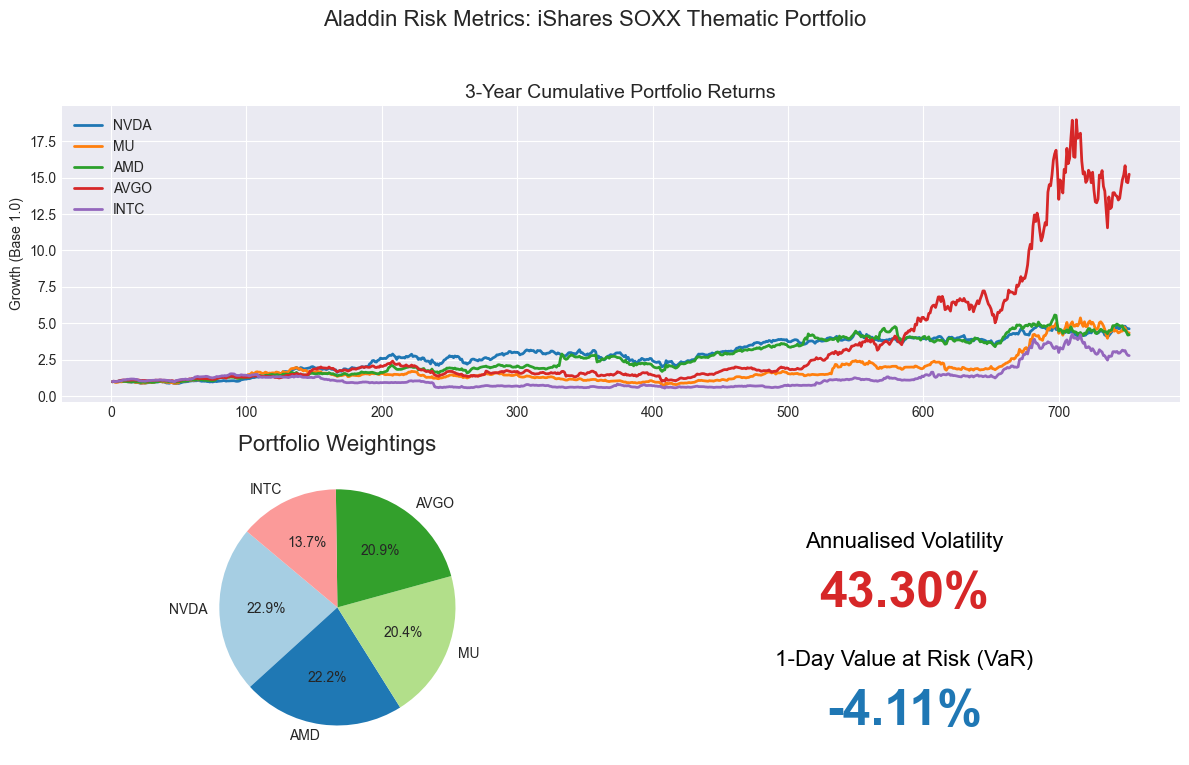

In [ ]:
#Setup the Dashboard Canvas
plt.style.use('seaborn-v0_8-darkgrid')
fig = plt.figure(figsize=(12, 8))
fig.suptitle('Aladdin Risk Metrics: iShares SOXX Thematic Portfolio', fontsize=16)

# Chart 1
# Cumulative Returns (Top Half)
ax1 = plt.subplot(2, 1, 1)
cumulative_returns = (1 + returns_df).cumprod()
for col in cumulative_returns.columns:
    ax1.plot(cumulative_returns.index, cumulative_returns[col], label=col, linewidth=2)
ax1.set_title('3-Year Cumulative Portfolio Returns', fontsize=14)
ax1.legend(loc='upper left', fontsize=10)
ax1.set_ylabel('Growth (Base 1.0)')

# Chart 2 
# Asset Allocation (Bottom Left)
ax2 = plt.subplot(2, 2, 3)
weights = [22.86, 22.17, 20.93, 20.36, 13.68]
labels = ['NVDA', 'AMD', 'AVGO', 'MU', 'INTC']
ax2.pie(weights, labels=labels, autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
ax2.set_title('Portfolio Weightings', fontsize=16)

# Chart 3
# Risk KPIs (Bottom Right)
ax3 = plt.subplot(2, 2, 4)
ax3.axis('off')
ax3.text(0.5, 0.7, 'Annualised Volatility', fontsize=16, ha='center', color='black')
ax3.text(0.5, 0.5, '43.30%', fontsize=36, ha='center', fontweight='bold', color='#d62728')
ax3.text(0.5, 0.3, '1-Day Value at Risk (VaR)', fontsize=16, ha='center', color='black')
ax3.text(0.5, 0.1, '-4.11%', fontsize=36, ha='center', fontweight='bold', color='#1f77b4')

# Show the dashboard
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('Aladdin_Risk_Dashboard.png', dpi=300)
plt.show()

In [9]:

print("Dashboard successfully generated and saved as 'Aladdin_Risk_Dashboard.png'!")

Dashboard successfully generated and saved as 'Aladdin_Risk_Dashboard.png'!
